# Selección de la iteración de LightGBM DART

Se entrena un único modelo desde cero con un máximo de 667 iteraciones. En cada iteración se registra el F1 macro en las mismas 20 personas utilizadas para comparar las épocas de la CRNN y se guarda el modelo cuando alcanza un nuevo máximo. Se conservan también los modelos de las iteraciones 300 y 667 para comparar el coste y las métricas.

Las 80 personas de entrenamiento y las 20 de evaluación coinciden con el notebook mixto. Al usar el grupo reservado para elegir la iteración, el mejor F1 es una métrica de selección. En caso de empate se conserva la primera iteración.

In [1]:
import csv
import hashlib
import json
import lightgbm as lgb
import matplotlib.pyplot as plt
import sys
from datetime import datetime
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from sklearn.model_selection import StratifiedKFold

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data.dvc').is_file())
sys.path.insert(0, str(ROOT/'packages/sleep-staging/src'))
from sleep_staging import PreprocessingConfig, PreprocessingPipeline
from sleep_staging.datasets import discover_sleep_cassette_records, discover_sleep_telemetry_records
from sleep_staging.training import create_lightgbm_classifier, load_or_build_supervised_dataset

DATA = ROOT/'data'
SPEC = json.loads((DATA/'experimentos/lightgbm_st_sc/experimento.json').read_text('utf8'))
CLASES = np.array(SPEC['classes'])
COLUMNAS = SPEC['feature_columns']
PERFILES = {c: SPEC['preprocessing_' + c.lower()] for c in ('Telemetry','Cassette')}
SEMILLA = 42
MAX_ITERACIONES = 667
manifest = json.loads((DATA/'experimentos/dart_crnn_mixto/dart_666_crnn_27_20261119_191036/referencia_seleccion_80_20.json').read_text('utf8'))

In [2]:
registros = {'Telemetry': discover_sleep_telemetry_records(DATA/'sleep-telemetry'),
             'Cassette': discover_sleep_cassette_records(DATA/'sleep-cassette')}
esperados = {'Cassette': (78, 153), 'Telemetry': (22, 44)}
for cohorte, lista in registros.items():
    assert (len({r.subject_id for r in lista}), len(lista)) == esperados[cohorte], cohorte
indices, tablas = [], []
for cohorte, lista in registros.items():
    pipeline = PreprocessingPipeline(PreprocessingConfig(**PERFILES[cohorte]))
    grupos = [lista] if cohorte == 'Telemetry' else [[r] for r in lista]
    cache = DATA/'processed/supervised'
    for posicion, grupo in enumerate(grupos, 1):
        ds = load_or_build_supervised_dataset(grupo, pipeline, cache, verbose=False)
        tablas.append(ds.features.reindex(columns=COLUMNAS).astype('float32'))
        indices.append(ds.metadata[['record_id','subject_id','epoch_index']].assign(cohorte=cohorte, etapa=ds.labels.to_numpy()))
        if posicion % 10 == 0 or posicion == len(grupos):
            print(f'{cohorte} · {posicion}/{len(grupos)} grupos procesados', flush=True)
X = pd.concat(tablas, ignore_index=True)
meta = pd.concat(indices, ignore_index=True)
del tablas, indices, ds
assert len(meta)==len(X) and not meta.duplicated(['record_id','epoch_index']).any()
assert sorted(meta.etapa.unique())==CLASES.tolist()
personas = meta[['cohorte','subject_id']].drop_duplicates().sort_values(['cohorte','subject_id'])
assert personas.subject_id.is_unique
assert set(meta.record_id) == {r.record_id for lista in registros.values() for r in lista}
_, idx_test = next(StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(personas, personas.cohorte))
prueba = meta.subject_id.isin(personas.iloc[idx_test].subject_id)
train, test = meta[~prueba], meta[prueba]
assert train.subject_id.nunique() == 80 and test.subject_id.nunique() == 20
assert set(train.subject_id).isdisjoint(test.subject_id)
resumen = meta.assign(particion=np.where(prueba,'Prueba','Entrenamiento')).groupby(['particion','cohorte']).agg(
    personas=('subject_id','nunique'), noches=('record_id','nunique'), segmentos=('etapa','size'))
display(resumen)
display(test.groupby('cohorte').agg(personas=('subject_id',lambda x: ', '.join(sorted(set(x)))),
                                    registros=('record_id',lambda x: ', '.join(sorted(set(x))))))
assert set(train.subject_id) == set(manifest['contrato']['personas_entrenamiento'])
assert set(train.record_id) == set(manifest['contrato']['registros_entrenamiento'])
assert len(train) == 365283 and len(test) == 92369

Telemetry · 1/1 grupos procesados


Cassette · 10/153 grupos procesados


Cassette · 20/153 grupos procesados


Cassette · 30/153 grupos procesados


Cassette · 40/153 grupos procesados


Cassette · 50/153 grupos procesados


... (9 outputs left out)

Cassette · 150/153 grupos procesados


Cassette · 153/153 grupos procesados


personas  noches  segmentos
particion     cohorte                               
Entrenamiento Cassette         62     122     330469
              Telemetry        18      36      34814
Prueba        Cassette         16      31      84492
              Telemetry         4       8       7877

,personas,registros
cohorte,,
Cassette,"SC401, SC403, SC404, SC407, SC418, SC419, SC42...","SC4011, SC4012, SC4031, SC4032, SC4041, SC4042..."
Telemetry,"S01, S02, S11, S19","ST7011, ST7012, ST7021, ST7022, ST7111, ST7112..."


## Seguimiento de las 667 iteraciones

LightGBM calcula las probabilidades de evaluación durante el propio ajuste. Cada punto de la curva corresponde al ensemble tal como estaba en esa iteración. Se conserva una copia de los árboles con los pesos de ese momento al alcanzar el mejor F1 y en las dos iteraciones de referencia. El tiempo acumulado incluye la evaluación y el seguimiento.

In [3]:
salida = ROOT/'Notebooks/experiments/auxiliares_dart_crnn/resultados_dart'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
salida.mkdir(parents=True, exist_ok=False)
x_train, x_test = X.loc[train.index], X.loc[test.index]
y_test = pd.Categorical(test.etapa, categories=CLASES).codes
config = dict(SPEC['parameters'], n_jobs=6, n_estimators=MAX_ITERACIONES)
modelo = create_lightgbm_classifier(**config)
historial = []
mejor_iteracion = 0
mejor_f1 = -np.inf
clases_numericas = np.arange(len(CLASES))

def evaluar_f1(real, probabilidades):
    pred = np.argmax(probabilidades, axis=1)
    f1 = f1_score(real, pred, labels=clases_numericas, average='macro', zero_division=0)
    return 'f1_macro', f1, True

def guardar_arboles(booster, ruta, iteracion):
    temporal = ruta.with_suffix('.tmp')
    booster.save_model(str(temporal), num_iteration=iteracion)
    temporal.replace(ruta)

def registrar_iteracion(env):
    global mejor_iteracion, mejor_f1
    iteracion = env.iteration + 1
    f1 = next(valor for grupo, metrica, valor, _ in env.evaluation_result_list
              if grupo == 'personas_reservadas' and metrica == 'f1_macro')
    if f1 > mejor_f1:
        mejor_f1, mejor_iteracion = f1, iteracion
        guardar_arboles(env.model, salida/'mejor_dart.txt', iteracion)
    if iteracion in (300, MAX_ITERACIONES):
        guardar_arboles(env.model, salida/f'dart_{iteracion}.txt', iteracion)
    fila = dict(iteracion=iteracion, f1_macro=f1, mejor_iteracion=mejor_iteracion, mejor_f1=mejor_f1,
                tiempo_acumulado_s=perf_counter()-inicio)
    historial.append(fila)
    with (salida/'curva.csv').open('a', newline='', encoding='utf8') as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=fila.keys())
        if iteracion == 1:
            escritor.writeheader()
        escritor.writerow(fila)
    print(f'Iteración {iteracion:3d}/{MAX_ITERACIONES} ({iteracion/MAX_ITERACIONES:.1%}) | F1 macro {f1:.4f} | mejor {mejor_f1:.4f} en iteración {mejor_iteracion}', flush=True)

print(f'DART desde cero con 80 personas y seguimiento en 20. Resultados en {salida.relative_to(ROOT)}', flush=True)
inicio = perf_counter()
modelo.fit(x_train, train.etapa, eval_set=[(x_test, test.etapa)], eval_names=['personas_reservadas'],
           eval_metric=evaluar_f1, callbacks=[registrar_iteracion])
np.testing.assert_array_equal(modelo.classes_, CLASES)
assert len(historial) == MAX_ITERACIONES

DART desde cero con 80 personas y seguimiento en 20. Resultados en Notebooks\auxiliares_dart_crnn\resultados_dart\20261119_184312_810426


E:\PROJECTS\Maestria Inteligencia Artificial\masterIADesarollo\micro-proyecto-grupo-7\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Iteración   1/667 (0.1%) | F1 macro 0.1541 | mejor 0.1541 en iteración 1


Iteración   2/667 (0.3%) | F1 macro 0.1541 | mejor 0.1541 en iteración 1


Iteración   3/667 (0.4%) | F1 macro 0.1541 | mejor 0.1541 en iteración 1


Iteración   4/667 (0.6%) | F1 macro 0.1541 | mejor 0.1541 en iteración 1


... (659 outputs left out)

Iteración 664/667 (99.6%) | F1 macro 0.7935 | mejor 0.7935 en iteración 662


Iteración 665/667 (99.7%) | F1 macro 0.7935 | mejor 0.7935 en iteración 662


Iteración 666/667 (99.9%) | F1 macro 0.7936 | mejor 0.7936 en iteración 666


Iteración 667/667 (100.0%) | F1 macro 0.7936 | mejor 0.7936 en iteración 666


## Comparación de los modelos guardados

Se vuelven a cargar los modelos de la mejor iteración, la 300 y la 667. El F1 macro se calcula directamente desde sus predicciones para comprobar que coincide con el valor registrado durante el entrenamiento.

,iteracion,f1_macro,exactitud,kappa,tiempo_s
modelo,,,,,
Mejor,666,0.7936,0.9059,0.8319,1604.4368
300 iteraciones,300,0.7820,0.8997,0.8206,659.6989
667 iteraciones,667,0.7936,0.9059,0.8319,1607.8070


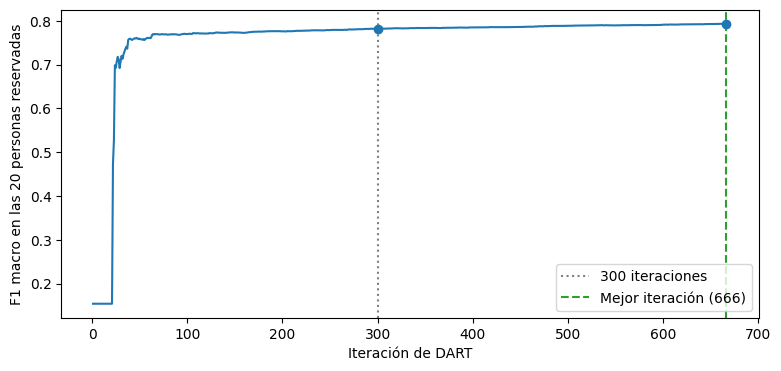

Mejor iteración: 666. F1 macro 0.7936.
Notebooks\auxiliares_dart_crnn\resultados_dart\20261119_184312_810426


In [4]:
curva = pd.DataFrame(historial).set_index('iteracion')
filas = []
for etiqueta, i, ruta in [('Mejor', mejor_iteracion, salida/'mejor_dart.txt'),
                          ('300 iteraciones', 300, salida/'dart_300.txt'),
                          ('667 iteraciones', MAX_ITERACIONES, salida/f'dart_{MAX_ITERACIONES}.txt')]:
    booster = lgb.Booster(model_file=str(ruta))
    assert booster.current_iteration() == i
    pred = booster.predict(x_test, num_threads=4).argmax(axis=1)
    f1 = f1_score(y_test, pred, labels=clases_numericas, average='macro', zero_division=0)
    np.testing.assert_allclose(f1, curva.at[i,'f1_macro'], rtol=0, atol=1e-10)
    filas.append(dict(modelo=etiqueta, iteracion=i, f1_macro=f1, exactitud=accuracy_score(y_test,pred),
                      kappa=cohen_kappa_score(y_test,pred), tiempo_s=curva.at[i,'tiempo_acumulado_s']))
comparacion = pd.DataFrame(filas).set_index('modelo')
display(comparacion.round(4))
comparacion.to_csv(salida/'comparacion.csv')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curva.index, curva.f1_macro)
ax.scatter([300, mejor_iteracion], curva.loc[[300, mejor_iteracion],'f1_macro'], zorder=3)
ax.axvline(300, color='grey', linestyle=':', label='300 iteraciones')
ax.axvline(mejor_iteracion, color='tab:green', linestyle='--', label=f'Mejor iteración ({mejor_iteracion})')
ax.set(xlabel='Iteración de DART', ylabel='F1 macro en las 20 personas reservadas')
ax.legend()
plt.show()

informe = dict(max_iteraciones=MAX_ITERACIONES, mejor_iteracion=mejor_iteracion, mejor_f1_macro=float(mejor_f1),
               personas_entrenamiento=sorted(train.subject_id.unique()), personas_prueba_usadas_para_seleccion=sorted(test.subject_id.unique()),
               firma_experimento_80_20=manifest['firma'], parametros=config,
               sha256_modelo=hashlib.sha256((salida/'mejor_dart.txt').read_bytes()).hexdigest())
(salida/'resumen.json').write_text(json.dumps(informe, ensure_ascii=False, indent=2), encoding='utf8')
print(f'Mejor iteración: {mejor_iteracion}. F1 macro {mejor_f1:.4f}.')
print(salida.relative_to(ROOT))